# SMC compartment: scVI integration of clean data

In [1]:
import sys 
import os
from datetime import datetime

import pandas as pd
import numpy as np
import scanpy as sc
import anndata as ad
import scvi
import hdf5plugin

import matplotlib.pyplot as plt
import seaborn as sns

# Add repo path to sys path (allows to access scripts and metadata from repo)
repo_path = os.path.split(os.getcwd())[0]
sys.path.insert(1, repo_path) 
sys.path.insert(2, '/lustre/scratch126/cellgen/team205/lm25/thymus_projects/thymus_ageing_atlas/General_analysis/scripts')

import torch
torch.cuda.is_available()

%reload_ext autoreload
%autoreload 2

from scvi_wrapper2 import run_scvi

In [2]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all" # to show output from all the lines in a cells
pd.set_option('display.max_column',None) # display all the columns in pandas
pd.options.display.max_rows = 100
import matplotlib
from matplotlib import rcParams
rcParams['pdf.fonttype'] = 42
sc.settings.set_figure_params(dpi = 150, color_map = 'RdPu', dpi_save = 150, vector_friendly = True, format = 'pdf')

In [3]:
# Define plot and path dirs
plot_path = os.path.join(repo_path, 'plots')
data_path = os.path.join(repo_path, 'data')
model_path = os.path.join(repo_path, 'models')
general_data_path = '/lustre/scratch126/cellgen/team205/lm25/thymus_projects/thymus_ageing_atlas/General_analysis/data'

In [4]:
def regen_embed (adata, anno2show):
    sc.pp.neighbors(adata, use_rep = 'X_scVI')
    sc.tl.umap(adata, min_dist = 0.1, spread = 1)
    sc.pl.umap(adata, color = anno2show)
    return (adata)

def ctypist_anno(adata, model, col_name, mv = False, clusters = None):
    import celltypist
    predictions = celltypist.annotate(adata, model=model, majority_voting = mv, over_clustering = clusters)
    predictions.to_adata(prefix=f'ctypist_{col_name}_')
    if mv:
        sc.pl.umap(adata, color = f'ctypist_{col_name}_majority_voting', frameon = False)
    else:
        sc.pl.umap(adata, color = f'ctypist_{col_name}_predicted_labels', frameon = False)

def run_leiden(adata, resolutions, key_name,restrict_to = None, legend_loc = "on data", legend_fontsize = 4):
    for r in resolutions:
        if restrict_to:
            sc.tl.leiden(adata, restrict_to = restrict_to, resolution = r, key_added = f'{key_name}-leiden_r{str(r)}',
                        flavor="igraph", n_iterations=2)
        else:
            sc.tl.leiden(adata, resolution = r, key_added = f'{key_name}-leiden_r{str(r)}',
                        flavor="igraph", n_iterations=2)
    sc.pl.umap(adata, color = [f'{key_name}-leiden_r{str(r)}' for r in resolutions] , legend_loc = legend_loc, legend_fontsize = legend_fontsize)

def remove_small_samples(adata, sample_anno = 'sample', less_than=3):
    samples2remove = adata.obs[sample_anno].value_counts().loc[(adata.obs[sample_anno].value_counts()<less_than)].index.tolist()
    print(samples2remove)
    n_cells_orig = adata.shape[0]
    adata = adata[~adata.obs[sample_anno].isin(samples2remove),:].copy()
    n_cells = adata.shape[0]
    print(f'{str(n_cells_orig-n_cells)} cells were removed')
    return(adata)

In [5]:
general_mrkrs = ['PTPRC', 'CD3G', 
               'HOXA9', 
               'HES1', #DN
               'RORC', #DP
               'CCR9',
              'PDCD1', #CD8aa
              'CD8A', 'CD8B', 
              'CD4', 'CD40LG', 
              'CRTAM', 'ANXA1', #memory
             'FOXP3', 'DHRS3', 
               'TRDC', #gama-delta 
              'EOMES', 'KLRD1', # NK cells
              'TNFSF11', # ILC
              'CD19', 'VPREB1', # pre-pro B cells
              'IGHD', 'IGHA1', 'IGHG1', 
              'CLEC9A', 'CLEC10A', 
              'LAMP3', 
             'LILRA4','S100A9', 'C1QA', 'TPSB2', 'ITGA2B', 'GYPA', 
              'PDGFRA', 'COLEC11', 'FBN1', 
              'RGS5', 'CDH5', 
               'LYVE1', 'EPCAM', 'PSMB11', 'DLK2', 'KRT14', 
               'CCL19', 'AIRE', 'KRT1', 'POU2F3',
               'MYOD1', 'NEUROG1']

In [6]:
smc_mrkrs_dict = {'smc': ['ACTA2', 'MYH11', 'RERGL', 'STEAP4', 'CASQ2'],
                  'pericyte': ['RGS5', 'PDGFRB','ABCC9', 'KCNJ8'],
                   'cytokine subtype': ['CCL19', 'CCL21'],
                  'large vessel': ['COL1A1', 'ELN', 'SULF1'],
                   'prolif': ['MKI67', 'TOP2A'],
                  }

smc_mrkrs=[]
[smc_mrkrs.extend(smc_mrkrs_dict[key]) for key in smc_mrkrs_dict.keys()]

[None, None, None, None, None]

In [7]:
smc_mrkrs_dict2 = {'smc': ['ACTA2', 'MYH11'], 
                   'art_smc': ['RERGL', 'CASQ2', 'KCNAB1'],
                   'ven_smc': ['HMCN2', 'FLNC'],
                  'pericyte': ['ABCC9', 'KCNJ8', 'RGS5', 'AGT'],
                   'peri-smc': ['PDGFRB', 'ACTA2', 'MYH11', 'STEAP4', 'PROCR', 'FGF7', 'CHRDL1'],
                   'cytokine subtype': ['CCL19', 'CCL21'],
                  'large vessel': ['COL1A1', 'ELN', 'SULF1'],
                   'prolif': ['MKI67', 'TOP2A'],
                  }

smc_mrkrs2=[]
[smc_mrkrs2.extend(smc_mrkrs_dict2[key]) for key in smc_mrkrs_dict2.keys()]

[None, None, None, None, None, None, None, None]

## Subset to SMC

In [10]:
# Load data
adata_stroma = ad.read_h5ad (f'/nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/data/objects/thyAgeing_scvi_v3_2024-11-05_tec-fb-vascSplit_v5_2layers_300epochs_2025-01-06.zarr')

stroma_obs = pd.read_csv(f'/nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/data/objects/thyAgeing_scvi_v3_2024-11-05_tec-fb-vascSplit_doubl_anno2_2025-01-07.csv', index_col = 0)

adata_stroma.obs[['stroma-anno2-coarse', 'stroma-anno2-granular', 'doublet', 'doublet_verbose']] = stroma_obs.reindex(adata_stroma.obs_names)[['stroma-anno2-coarse', 'stroma-anno2-granular', 'doublet', 'doublet_verbose']].copy()

/tmp/ipykernel_3209393/2605147994.py:4: DtypeWarning: Columns (5,6,7,8,9,14,15,17,20,21,34,35,36,45,46,47,48,49,50) have mixed types. Specify dtype option on import or set low_memory=False.
  stroma_obs = pd.read_csv(f'/nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/data/objects/thyAgeing_scvi_v3_2024-11-05_tec-fb-vascSplit_doubl_anno2_2025-01-07.csv', index_col = 0)


In [11]:
adata_stroma.obs['stroma-anno2-coarse'].value_counts()

stroma-anno2-coarse
TEC         90001
Fb          71301
EC          54352
SMC         14331
Pericyte    12655
doublet      7555
TEC-EMT      4490
Name: count, dtype: int64

In [16]:
del adata_stroma
import gc
gc.collect()

111315

In [12]:
adata = adata_stroma[adata_stroma.obs['stroma-anno2-coarse'].isin(['SMC', 'Pericyte',]).copy()]

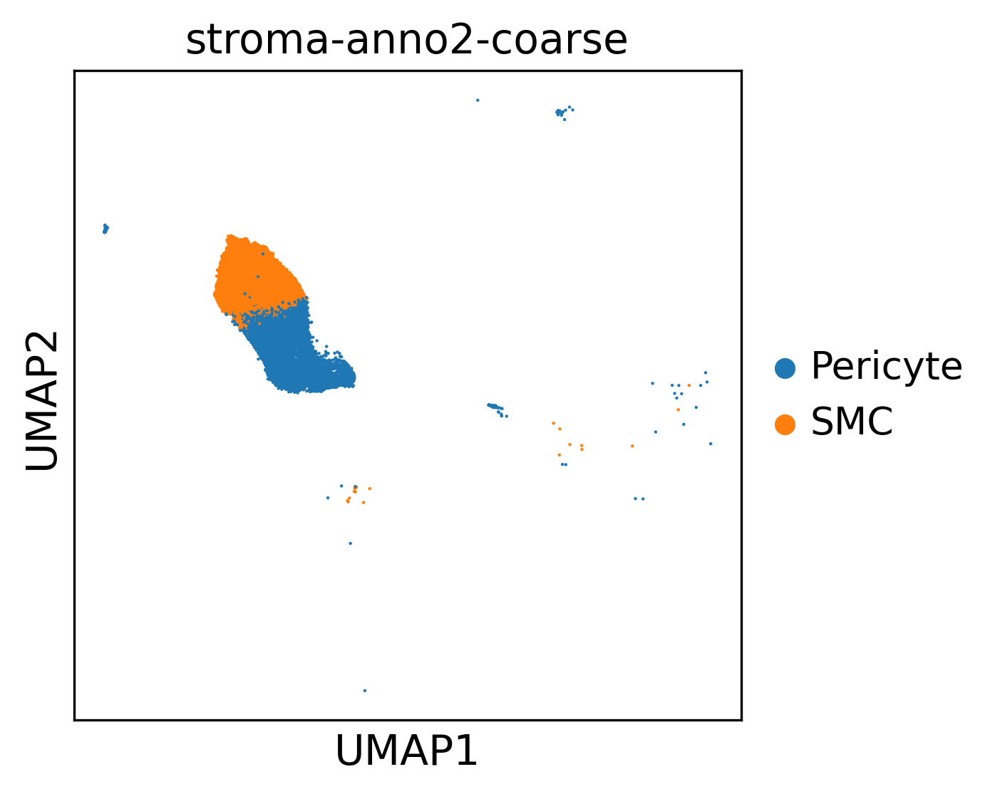

In [14]:
sc.pl.umap(adata, color = ['stroma-anno2-coarse'])

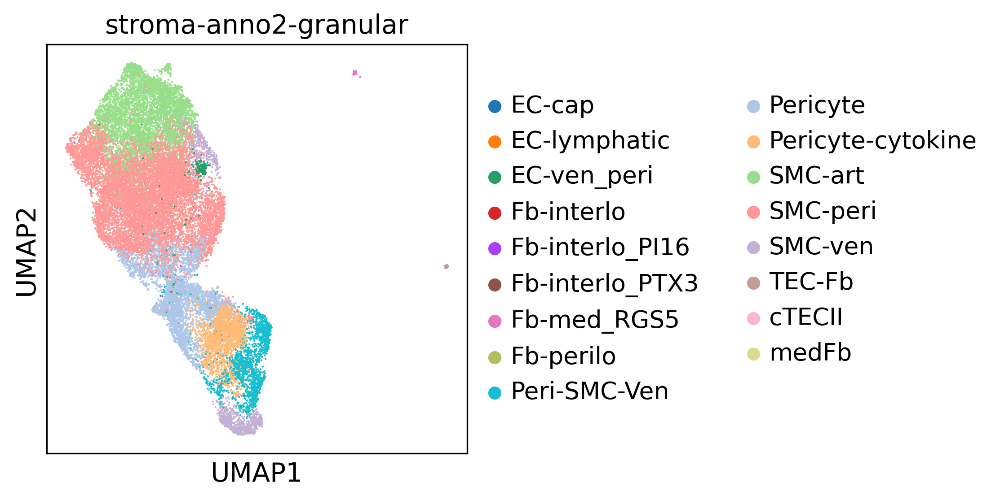

AnnData object with n_obs × n_vars = 26986 × 35530
    obs: 'barcode', 'sample', 'library', 'index', 'library_tcr_ab', 'library_tcr_gd', 'library_bcr', 'path_raw_gex', 'starsolo_version', 'path_cellbender_gex', 'path_cellranger_arc', 'donor', 'chemistry_simple', 'chemistry_detail', 'chemistry_orig', 'origin_institute', 'research_no', 'study', 'sort', 'sort_type', 'in_HTSA', 'public_data', 'type', 'cite', 'health_status', 'age_group', 'age_group2', 'age', 'age_num', 'age_unit', 'age_cont', 'sex', 'age_months', 'path_tcr_ab', 'path_tcr_gd', 'path_bcr', 'comment', 'n_counts', 'n_genes', 'percent_mito', 'percent_ribo', 'percent_hb', 'scrublet_score', 'predicted_doublet', 'taa_l5', 'taa_l4', 'taa_l3', 'taa_l2', 'taa_l1', 'taa_l0', 'doublet', 'stroma-anno1-coarse', 'stroma-anno1-granular', 'stroma-anno2-coarse', 'stroma-anno2-granular', 'doublet_verbose'
    var: 'gene_ids', 'gene_name', 'n_counts', 'n_cells'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'age_group_colors', 'chemistry_simple_

In [15]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
regen_embed(adata, anno2show = 'stroma-anno2-granular')

In [17]:
adata.obs['sample'].value_counts().loc[(adata.obs['sample'].value_counts()<3)].index.tolist()

['A16_TH_TOT_2',
 'Z17-THY-0-SC-2',
 'A45-THY-CD45N-5GEX',
 'Thy5',
 'A72-THY-0-SC-1',
 'Thy14',
 'U40-THY-0-SC-F-2',
 'Z12-THY--SC-EPCP-1',
 'Z13-THY--SC-2',
 'Z12-THY--SC-1',
 'A16_TH_TOT_5GEX_1',
 'Thy12',
 'Thy9',
 'Z11-THY--SC-1',
 'Z12-THY--SC-EPCP-2']

In [19]:
print(adata.shape[0])
samples2remove = adata.obs['sample'].value_counts().loc[(adata.obs['sample'].value_counts()<3)].index.tolist()
adata = adata[~adata.obs['sample'].isin(samples2remove),:].copy()
adata.shape

26986


(26961, 35530)

In [20]:
adata.obs['age_group'].value_counts()

age_group
adult     21595
infant     4525
paed        841
Name: count, dtype: int64

Removed excluded genes


An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


Highly variable genes selected in total (26961, 10000)


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/nfs/team205/vk8/mambaforge/envs/scvi-env3/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:441: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=4` in the `DataLoader` to improve performance.
/nfs/team205/vk8/mambaforge/envs/scvi-env3/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:441: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=4` in the `DataLoader` to improve performance.


Epoch 300/300: 100%|██| 300/300 [12:44<00:00,  2.63s/it, v_num=1, train_loss_step=2.16e+3, train_loss_epoch=2.15e+3]

`Trainer.fit` stopped: `max_epochs=300` reached.


Epoch 300/300: 100%|██| 300/300 [12:44<00:00,  2.55s/it, v_num=1, train_loss_step=2.16e+3, train_loss_epoch=2.15e+3]
scVI model trained
UMAP performed


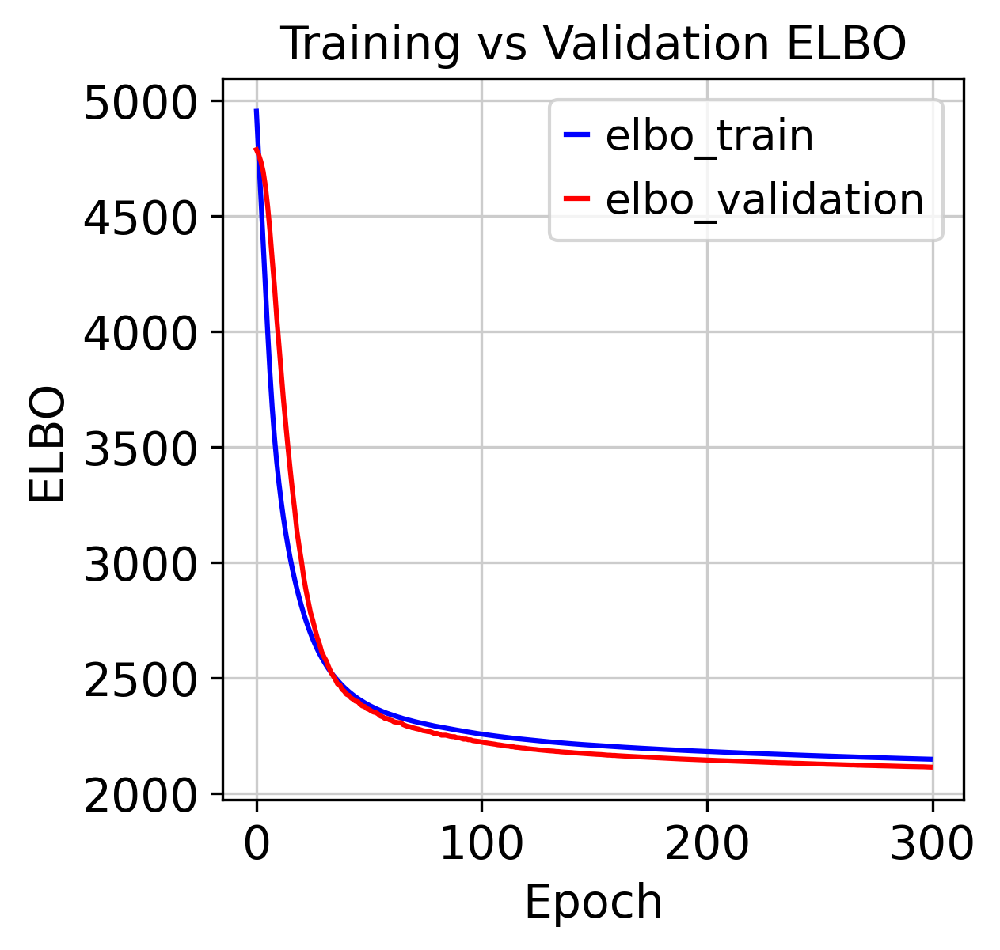

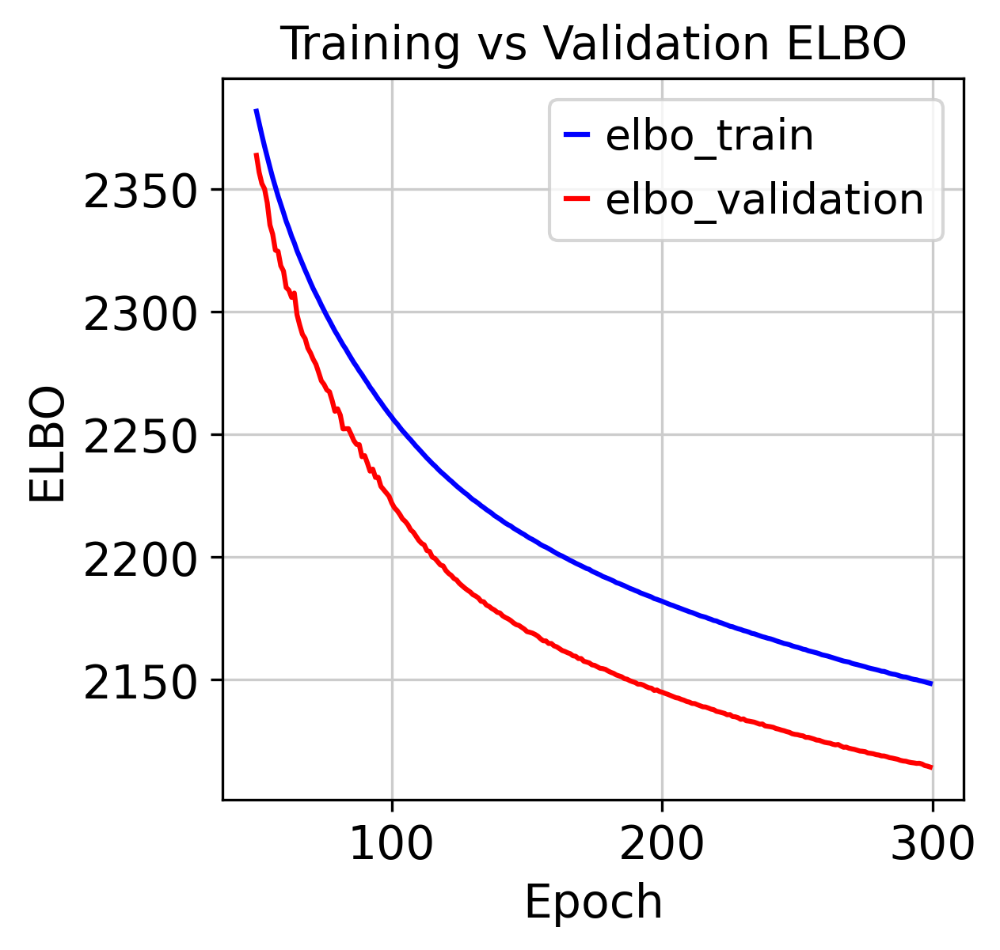

Plotting doublet_metric
Plotting age
Plotting batch_mixing
Plotting cat_covs
Plotting cont_covs


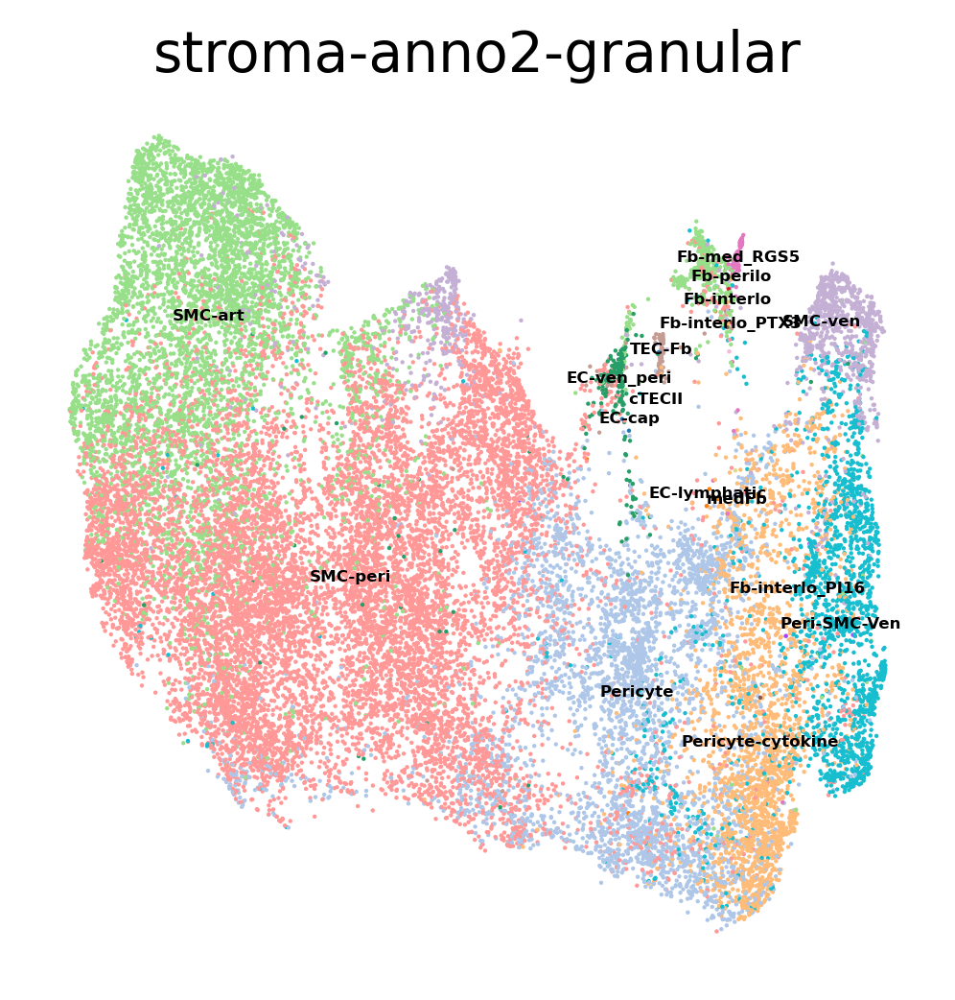

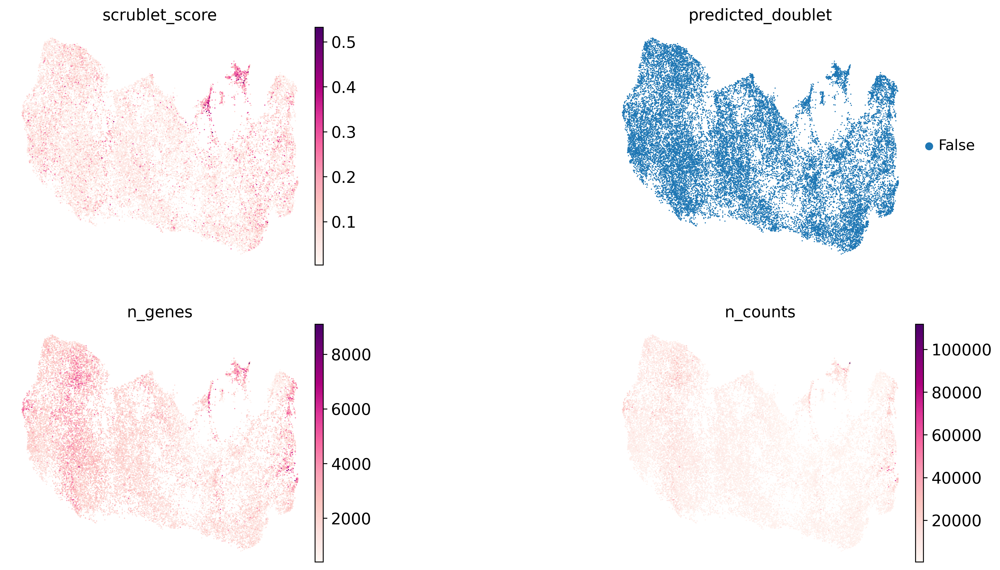

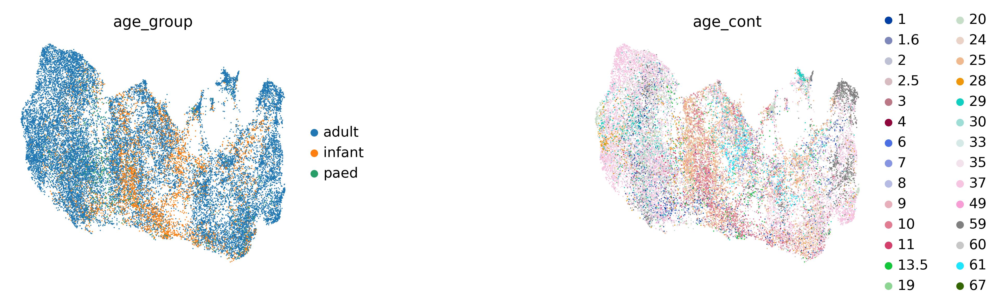

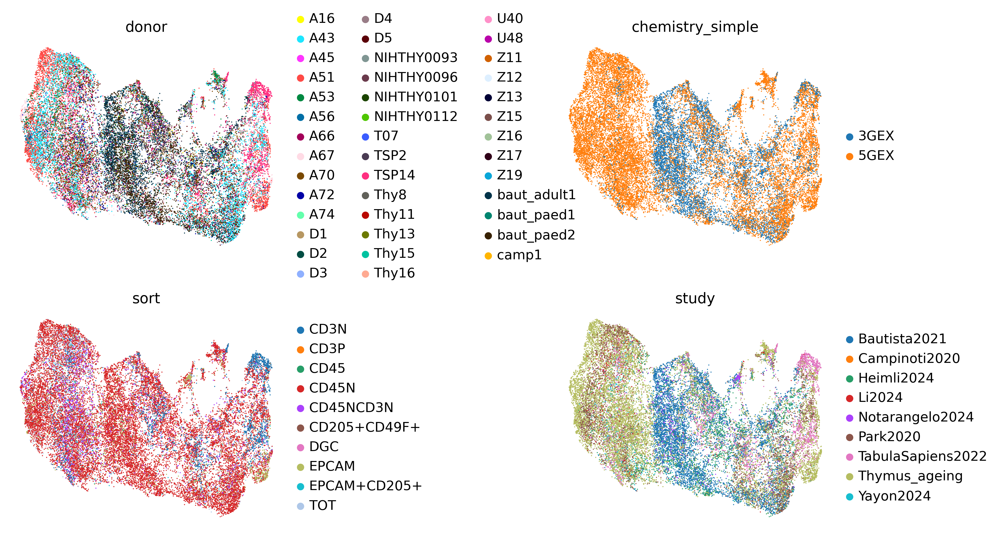

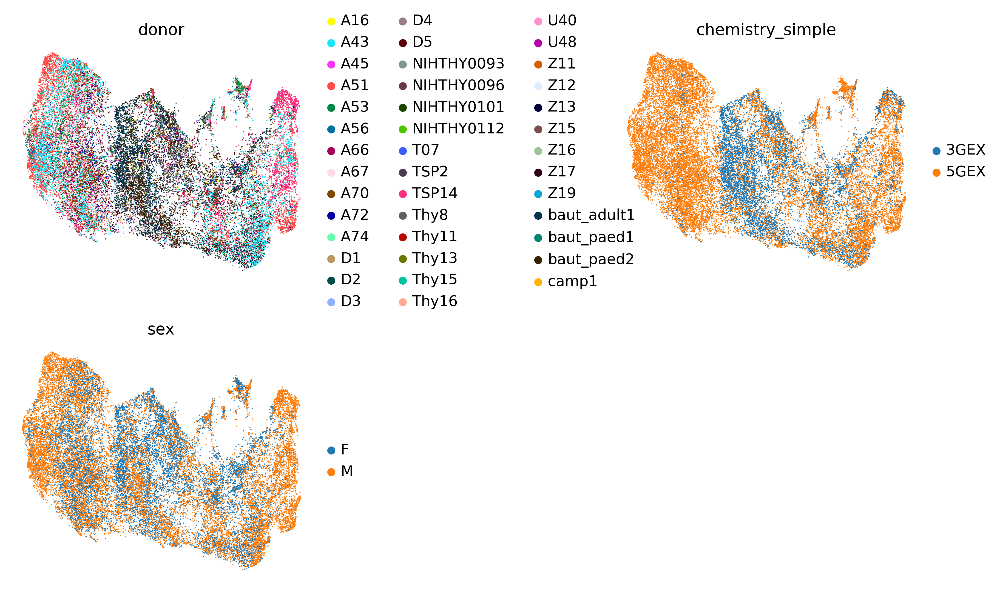

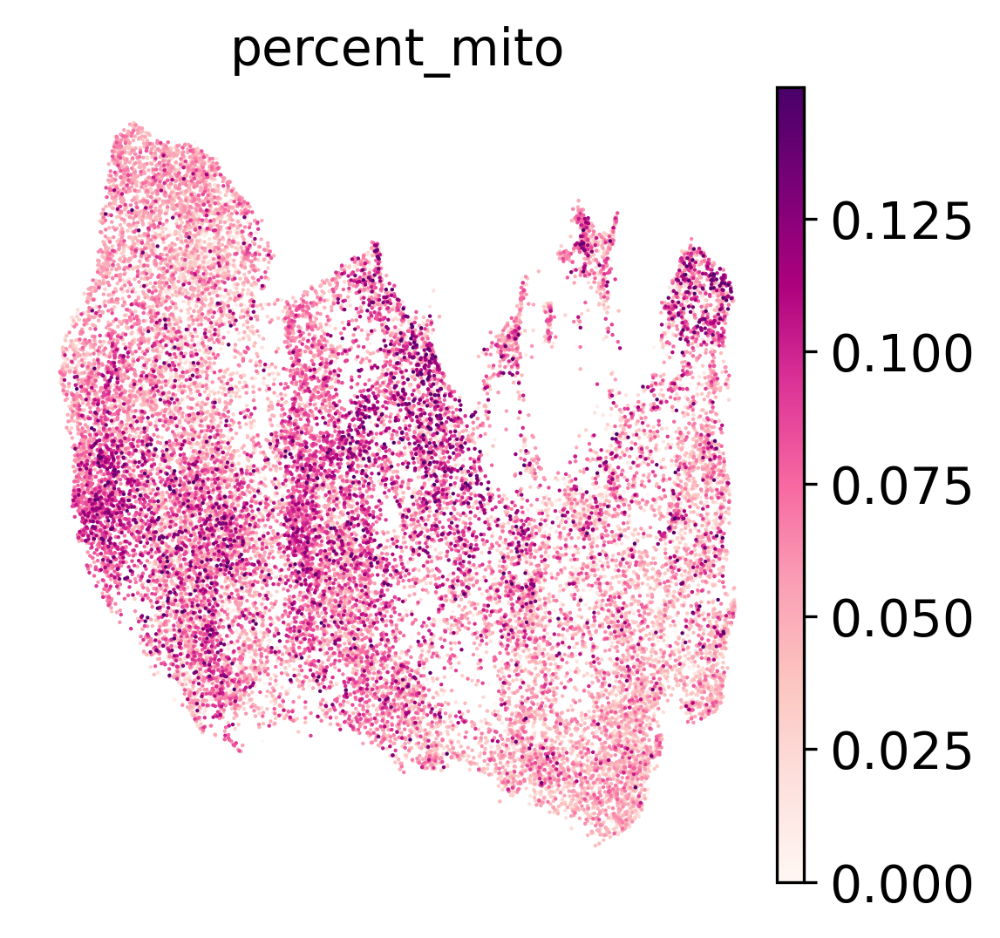

In [21]:
scvi_run2 = run_scvi(adata, 
                    # Excluded genes
                    include_genes=[], exclude_cc_genes=True, exclude_mt_genes=True, 
                    exclude_vdjgenes = True, remove_cite = False,
                    # Highly variable gene selection
                    batch_hv="age_group", hvg = 10000, span = 0.5,
                    # scVI 
                    batch_scvi="sample",
                    cat_cov_scvi=["donor", "chemistry_simple", "sex"], 
                    max_epochs=300, batch_size=2000, early_stopping = False, # early_stopping_patience = 15, early_stopping_min_delta = 10,
                    plan_kwargs = {'lr': 0.0001}, n_layers = 2, n_latent = 30, dispersion = 'gene-batch',
                                      check_val_every_n_epoch = 1,
                    # Leiden clustering
                    leiden_clustering = None, col_cell_type = 'stroma-anno2-granular',
                   covs = {'doublet_metric': ['scrublet_score', 'predicted_doublet', 'n_genes', 'n_counts'],
                    'age': ['age_group', 'age_cont'],
                    'batch_mixing': ['donor', 'chemistry_simple', 'sort', 'study']})

In [23]:
adata = scvi_run2['data'].copy()

In [ ]:
scvi_run2['data'].obs[]

In [34]:
def convert_colobj2str (adata):
    for col in adata.obs.columns:
        if adata.obs[col].dtype == 'O':
            adata.obs[col] = adata.obs[col].astype(str).copy()

In [29]:
for col in scvi_run2['data'].obs.columns:
    if scvi_run2['data'].obs[col].dtype == 'O':
        scvi_run2['data'].obs[col] =  scvi_run2['data'].obs[col].astype(str).copy()
        

In [37]:
convert_colobj2str(scvi_run2['vae'].adata)

In [38]:
# Save adata and scvi model
scvi_embed_version = 'scvi_v3_2024-11-05_tec-fb-vascSplit'
scvi_obj_version = f'smc-pc_v2_2layers_300epochs_batch-sample{datetime.now().strftime("%Y-%m-%d")}'
overwrite = True

#anno_cols = [c for c in scvi_run['data'].obs.columns if '_pred_' in c or '_prop_' in c]
if not os.path.exists(f'{data_path}/objects/thyAgeing_{scvi_embed_version}_{scvi_obj_version}.zarr') or overwrite:
#    scvi_run['data'].obs = scvi_run['data'].obs.drop(columns=anno_cols)
    scvi_run2['data'].write_h5ad(
        f'{data_path}/objects/thyAgeing_{scvi_embed_version}_{scvi_obj_version}.zarr',
        compression=hdf5plugin.FILTERS["zstd"],
        compression_opts=hdf5plugin.Zstd(clevel=5).filter_options,
    )
    scvi_run2['vae'].save(f'{model_path}/thyAgeing_{scvi_embed_version}_{scvi_obj_version}', save_anndata=True, overwrite=False)
else:
    print('File already exists')

## Redo annotation with celltypist and KNN transfer 

In [7]:
data_path

'/nfs/team205/vk8/projects/thymus_ageing_atlas/FB_Vascular_compartment/data'

In [8]:
adata = ad.read_h5ad(f'{data_path}/objects/thyAgeing_scvi_v3_2024-11-05_tec-fb-vascSplit_smc-pc_v2_2layers_300epochs_batch-sample2025-01-27.zarr')

🔬 Input data has 26961 cells and 35530 genes
🔗 Matching reference genes in the model
🧬 6783 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Detected a neighborhood graph in the input object, will run over-clustering on the basis of it
⛓️ Over-clustering input data with resolution set to 15
🗳️ Majority voting the predictions
✅ Majority voting done!


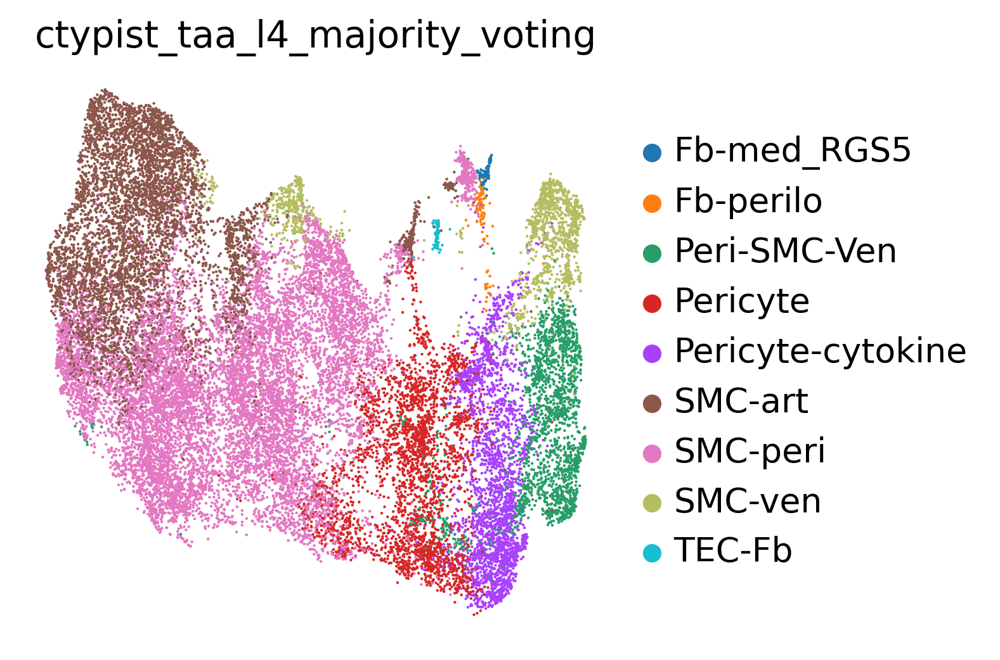

In [12]:
import celltypist
model_taa_l4 = celltypist.Model.load('/lustre/scratch126/cellgen/team205/lm25/thymus_projects/thymus_ageing_atlas/General_analysis/models/Celltypist_mod_thyAge_scvi_v2_pop_mrkrs_taa_l4_2024-12-10.pkl')
ctypist_anno(adata, model = model_taa_l4, col_name = 'taa_l4', mv = True)

🔬 Input data has 26961 cells and 35530 genes
🔗 Matching reference genes in the model
🧬 3520 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Detected a neighborhood graph in the input object, will run over-clustering on the basis of it
⛓️ Over-clustering input data with resolution set to 15
🗳️ Majority voting the predictions
✅ Majority voting done!


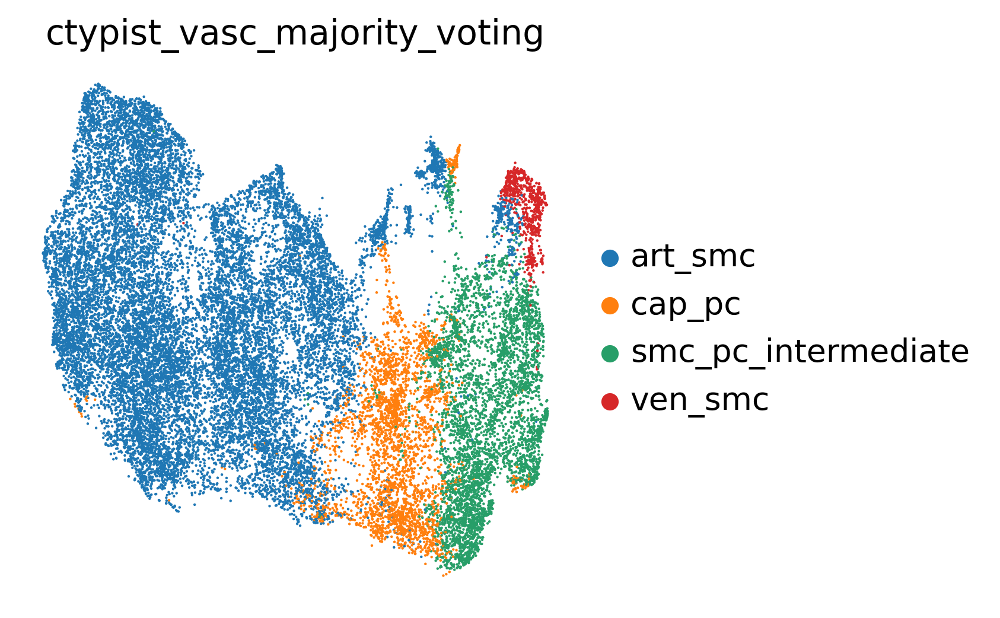

In [14]:
from celltypist import models
vasc_model = models.Model.load(model = 'Adult_Human_Vascular.pkl')
ctypist_anno (adata, model = vasc_model, col_name = 'vasc', mv=True)

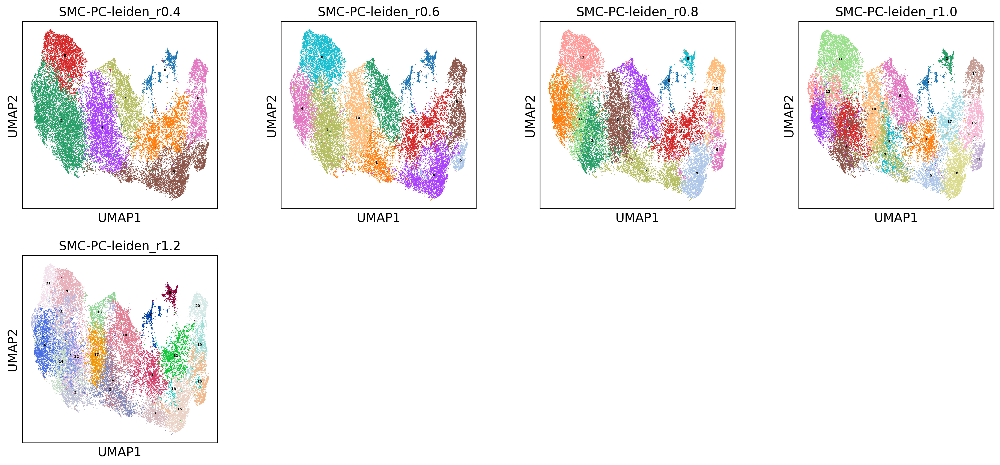

In [16]:
run_leiden(adata, resolutions=[0.4, 0.6, 0.8, 1.0, 1.2], key_name = 'SMC-PC')

In [30]:
dblt_mrkrs = ['PDGFRA', 'FBN1', 'CDH5', 'PECAM1', 'VWF', 'EPCAM', 'KRT5', 'KRT8']

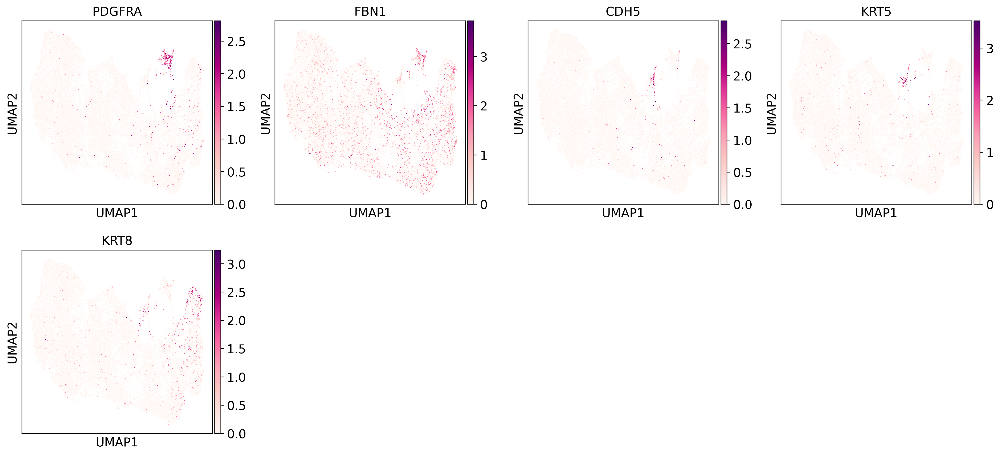

In [19]:
sc.pl.umap(adata, color = dblt_mrkrs)

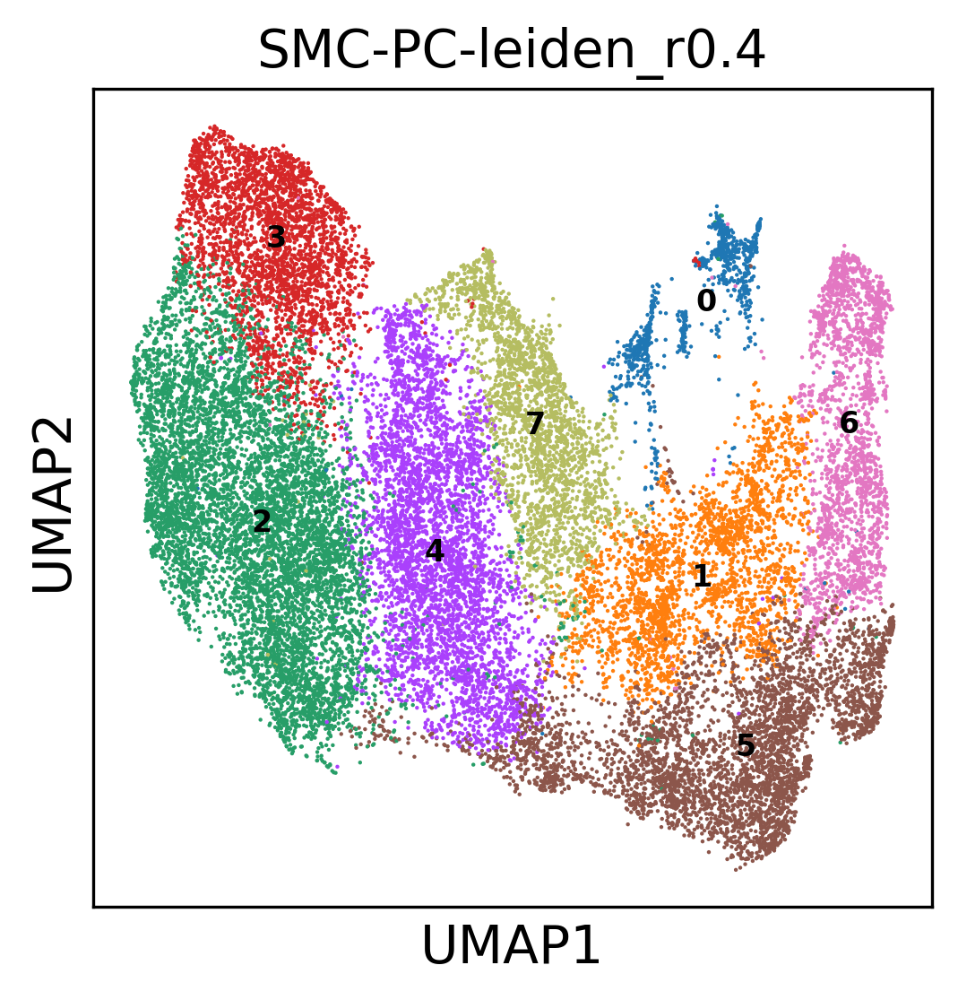

In [27]:
sc.pl.umap(adata, color = ['SMC-PC-leiden_r0.4'], legend_loc = 'on data', legend_fontsize = 8)

In [36]:
adata.obs.columns

Index(['barcode', 'sample', 'library', 'index', 'library_tcr_ab',
       'library_tcr_gd', 'library_bcr', 'path_raw_gex', 'starsolo_version',
       'path_cellbender_gex', 'path_cellranger_arc', 'donor',
       'chemistry_simple', 'chemistry_detail', 'chemistry_orig',
       'origin_institute', 'research_no', 'study', 'sort', 'sort_type',
       'in_HTSA', 'public_data', 'type', 'cite', 'health_status', 'age_group',
       'age_group2', 'age', 'age_num', 'age_unit', 'age_cont', 'sex',
       'age_months', 'path_tcr_ab', 'path_tcr_gd', 'path_bcr', 'comment',
       'n_counts', 'n_genes', 'percent_mito', 'percent_ribo', 'percent_hb',
       'scrublet_score', 'predicted_doublet', 'taa_l5', 'taa_l4', 'taa_l3',
       'taa_l2', 'taa_l1', 'taa_l0', 'doublet', 'stroma-anno1-coarse',
       'stroma-anno1-granular', 'stroma-anno2-coarse', 'stroma-anno2-granular',
       'doublet_verbose', 'ctypist_taa_l4_predicted_labels',
       'ctypist_taa_l4_over_clustering', 'ctypist_taa_l4_majority_voting

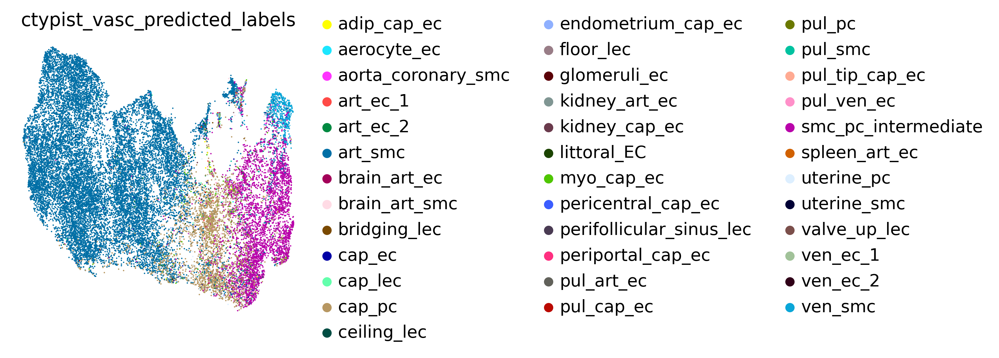

In [38]:
sc.pl.umap(adata, color = ['ctypist_vasc_predicted_labels'], frameon = False)

In [29]:
sc.tl.dendrogram(adata, groupby = 'SMC-PC-leiden_r0.4', use_rep = 'X_scVI')
sc.tl.dendrogram(adata, groupby = 'SMC-PC-leiden_r1.0', use_rep = 'X_scVI')

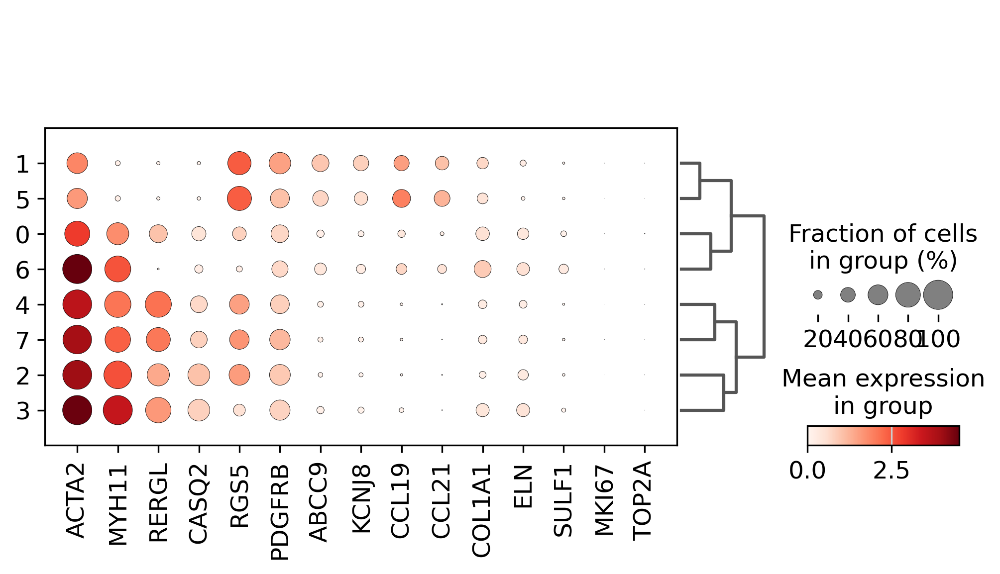

In [23]:
sc.pl.dotplot(adata, var_names = smc_mrkrs, groupby = 'SMC-PC-leiden_r0.4', dendrogram = True)

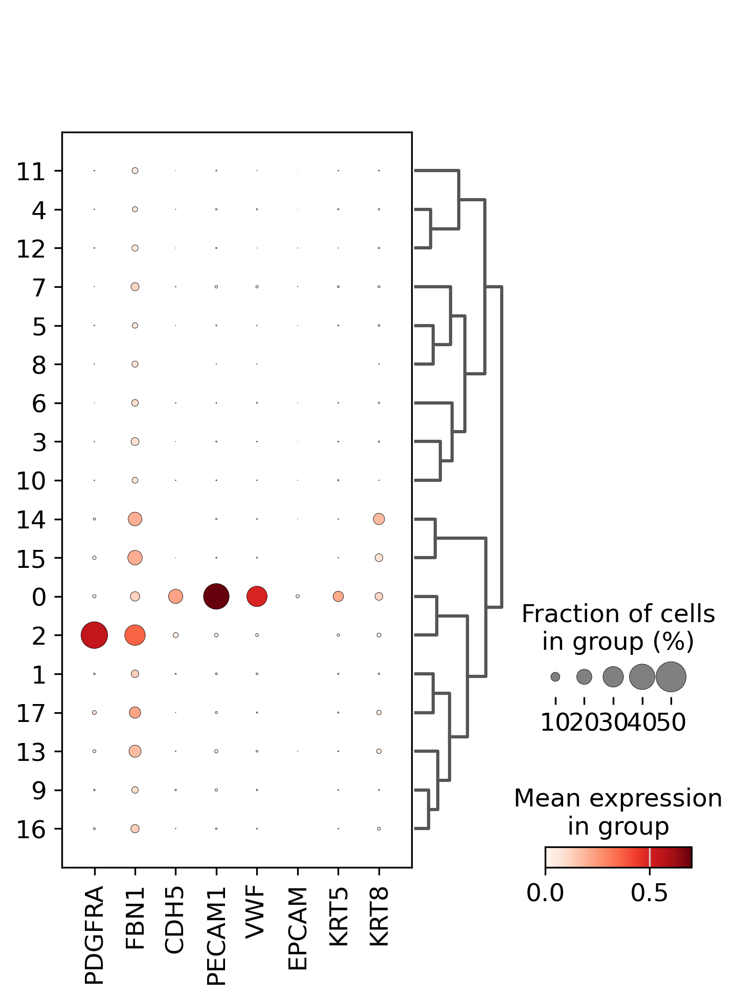

In [31]:
sc.pl.dotplot(adata, var_names = dblt_mrkrs, groupby = 'SMC-PC-leiden_r1.0', dendrogram = True)

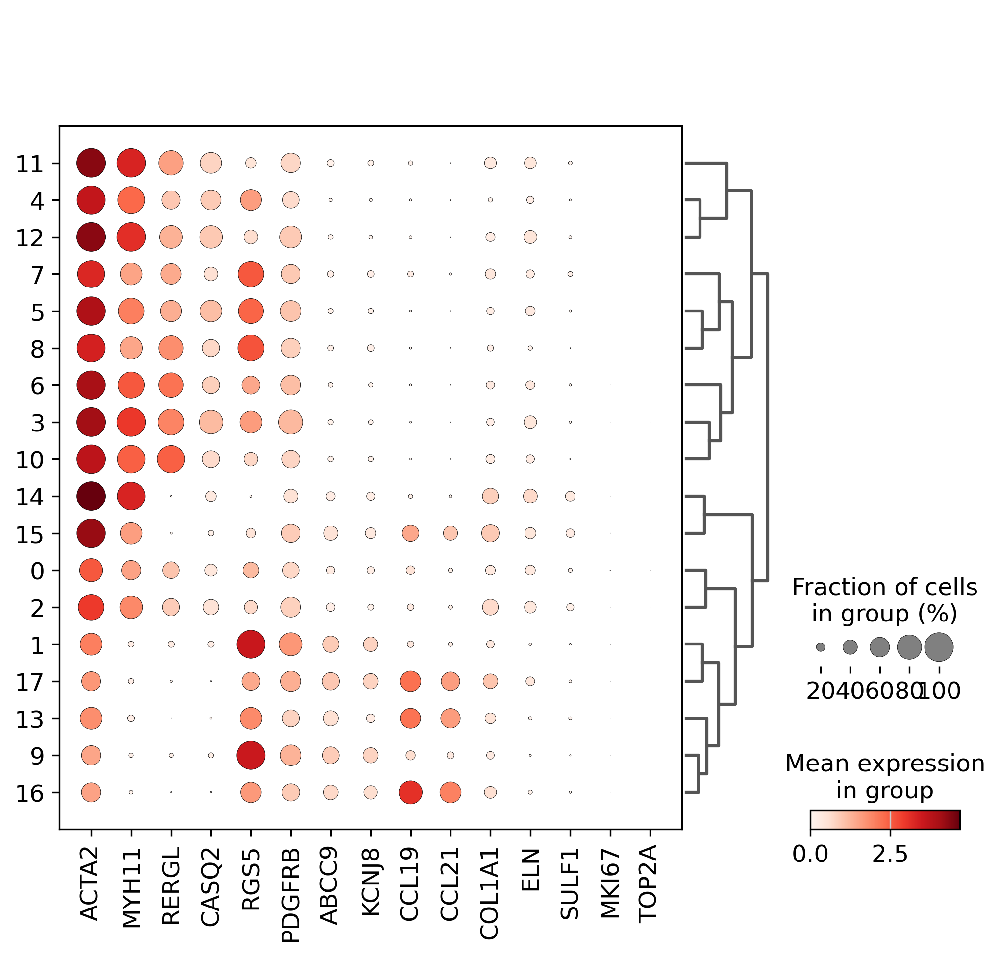

In [32]:
sc.pl.dotplot(adata, var_names = smc_mrkrs, groupby = 'SMC-PC-leiden_r1.0', dendrogram = True)

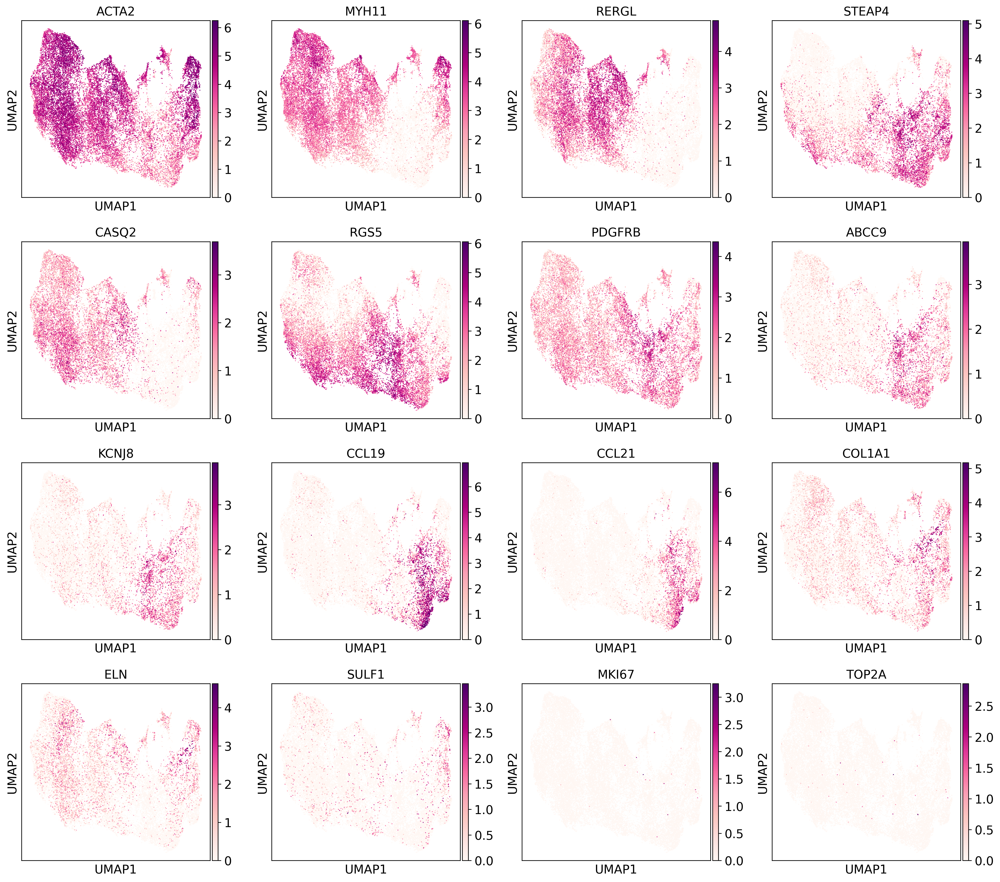

In [40]:
sc.pl.umap(adata, color = smc_mrkrs)

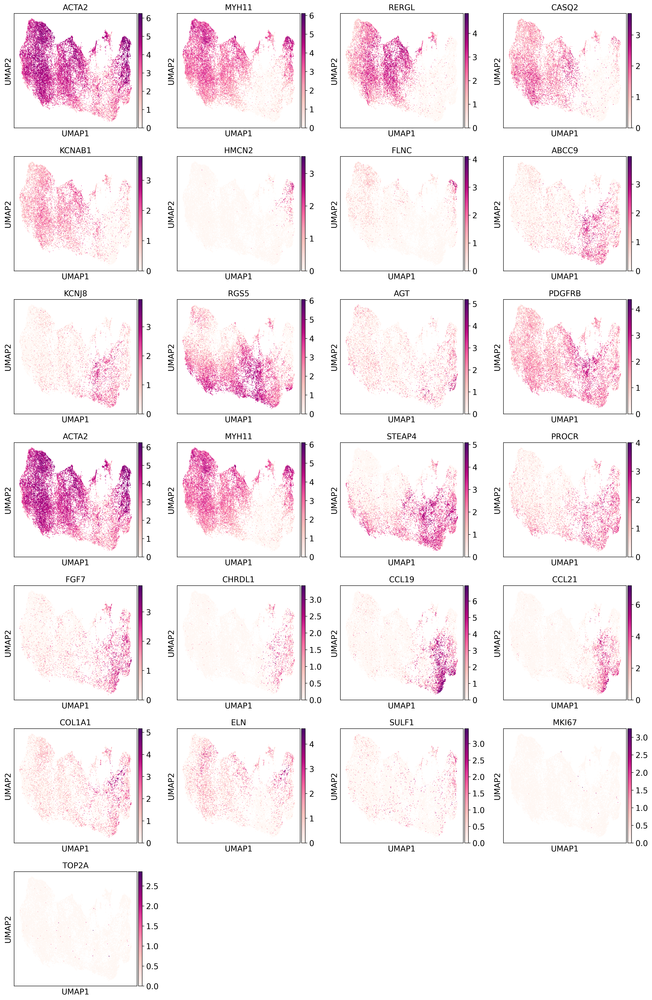

In [42]:
sc.pl.umap(adata, color = smc_mrkrs2)

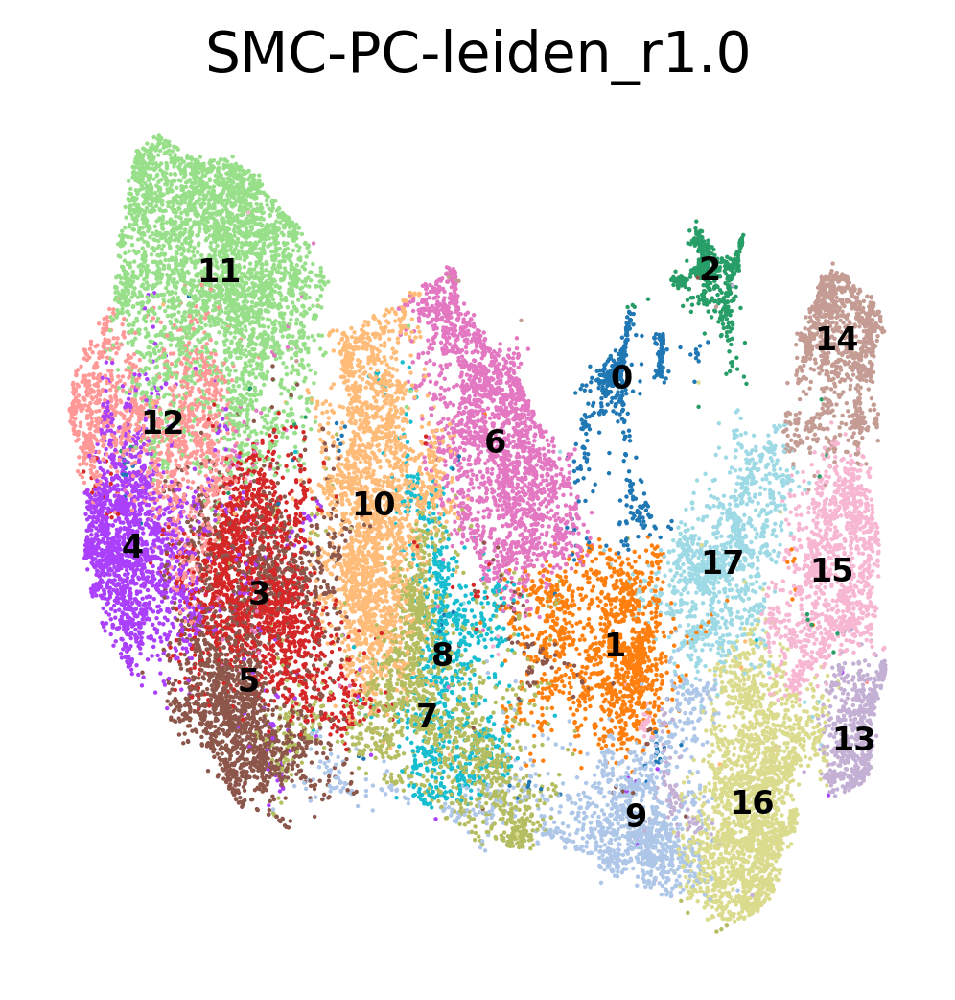

In [34]:
sc.pl.umap(adata, color = ['SMC-PC-leiden_r1.0'], legend_loc = 'on data', legend_fontsize = 8, frameon = False)

### Use markers to clarify doublets as well as annotations from vasculature atlas (https://www.nature.com/articles/s41591-024-03376-x)

In [44]:
adata.obs['SMC-PC_anno1'] = adata.obs.apply(lambda x: 'SMC-EC-doublet' if x['SMC-PC-leiden_r1.0'] == '0' else
                                                     'SMC-Fb-doublet' if x['SMC-PC-leiden_r1.0'] == '2' else
                                                      'SMC-ven' if x['SMC-PC-leiden_r1.2'] == '20' else
                                                     x['ctypist_vasc_majority_voting'], axis = 1)

... storing 'SMC-PC_anno1' as categorical


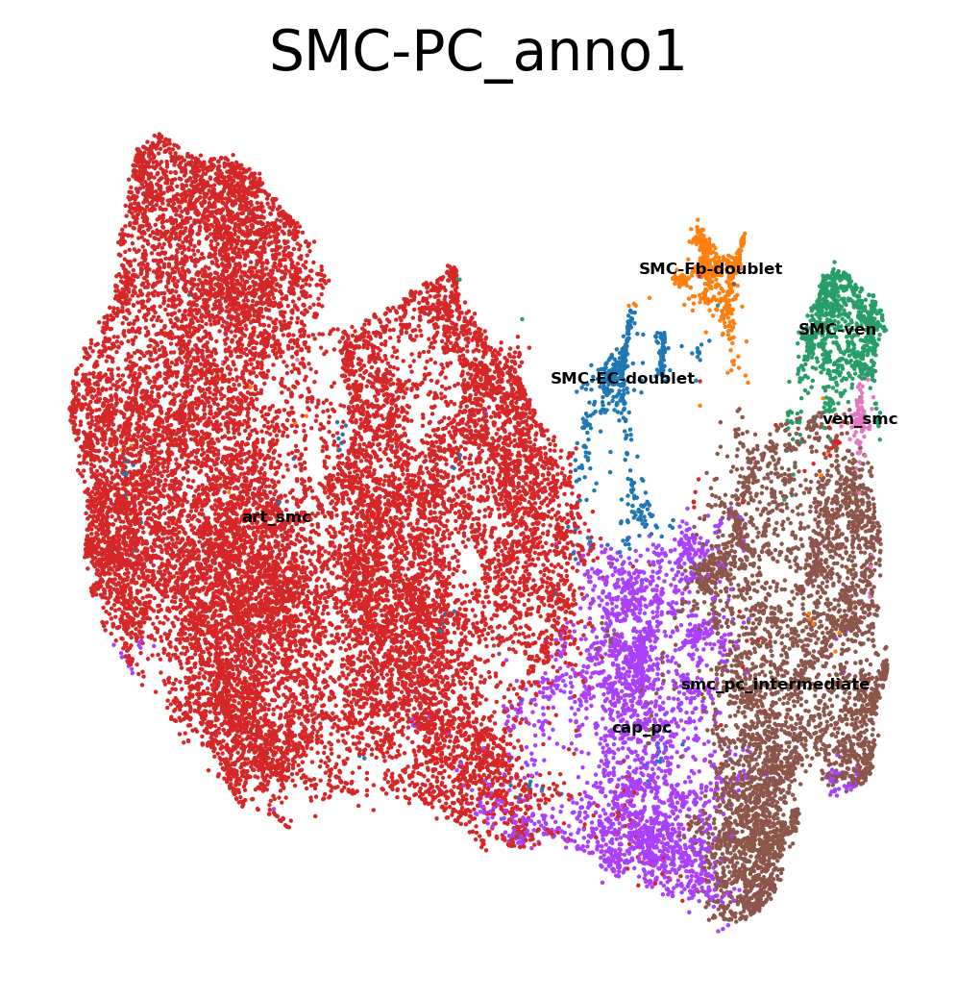

In [45]:
sc.pl.umap(adata, color = ['SMC-PC_anno1'], legend_loc = 'on data', legend_fontsize = 4, frameon = False)

In [46]:
adata.obs['SMC-PC_anno1'].cat.categories

Index(['SMC-EC-doublet', 'SMC-Fb-doublet', 'SMC-ven', 'art_smc', 'cap_pc',
       'smc_pc_intermediate', 'ven_smc'],
      dtype='object')

In [58]:
adata.obs['SMC-PC_anno'] = adata.obs['SMC-PC_anno1'].apply(lambda x: 'SMC-art' if x == 'art_smc' else
                                                          'Peri-cap' if x == 'cap_pc' else
                                                          'Peri-smc-interm' if x == 'smc_pc_intermediate' else
                                                          'SMC-ven' if x == 'ven_smc' else x)

... storing 'SMC-PC_anno' as categorical


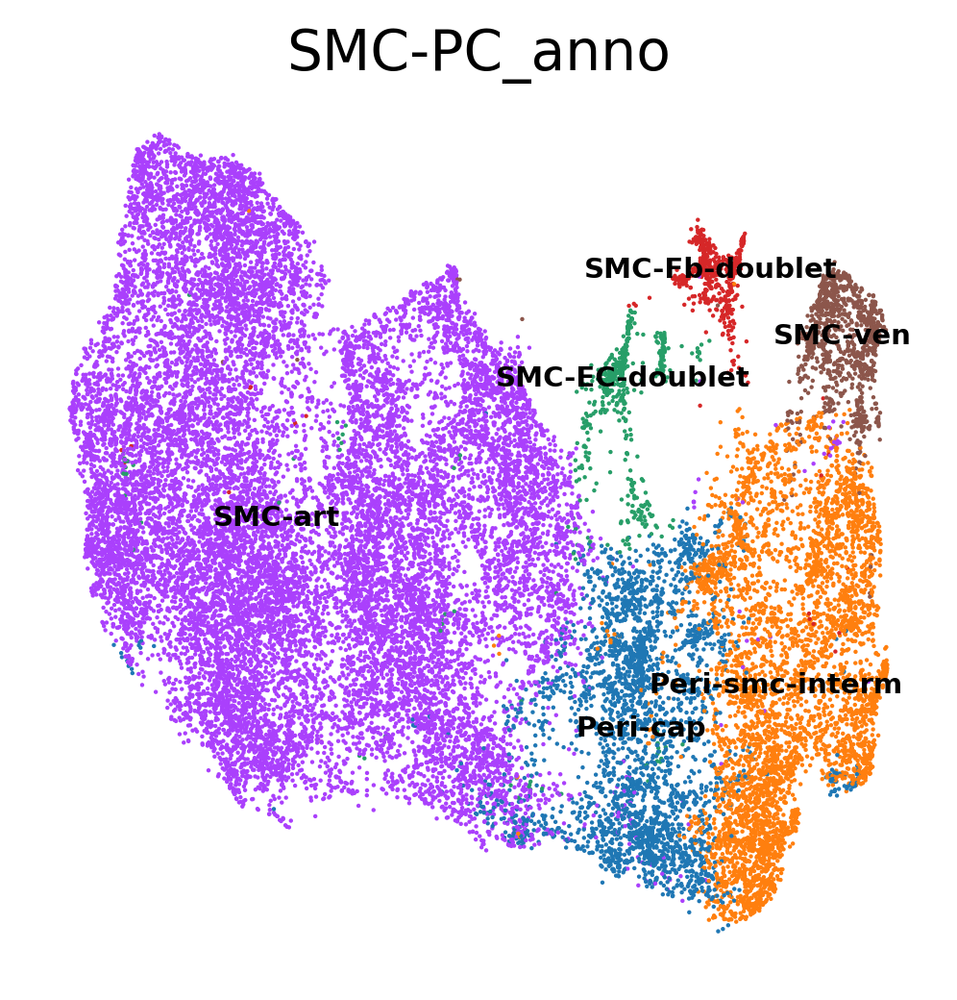

In [59]:
sc.pl.umap(adata, color = ['SMC-PC_anno'], legend_loc = 'on data', legend_fontsize = 7, frameon = False)

In [70]:
annotations = adata.obs[['SMC-PC_anno1', 'SMC-PC_anno']].copy()

In [60]:
adata.obs[['SMC-PC_anno1', 'SMC-PC_anno']].to_csv(f'{data_path}/objects/thyAgeing_smc-pc_v2_2layers_300epochs_batch-sample2025-01-27_anno1.csv')

In [61]:
doublet_clusters = [i for i in adata.obs['SMC-PC_anno'].cat.categories if 'doublet' in i]

In [62]:
adata_dbrm = adata[~adata.obs['SMC-PC_anno'].isin(doublet_clusters),].copy()

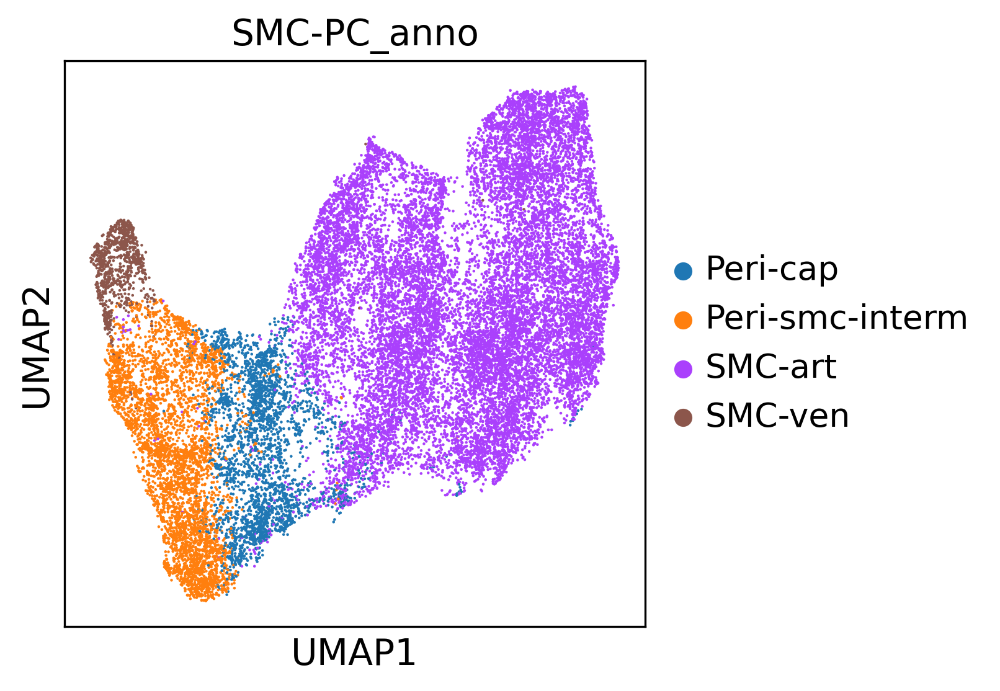

AnnData object with n_obs × n_vars = 25833 × 35530
    obs: 'barcode', 'sample', 'library', 'index', 'library_tcr_ab', 'library_tcr_gd', 'library_bcr', 'path_raw_gex', 'starsolo_version', 'path_cellbender_gex', 'path_cellranger_arc', 'donor', 'chemistry_simple', 'chemistry_detail', 'chemistry_orig', 'origin_institute', 'research_no', 'study', 'sort', 'sort_type', 'in_HTSA', 'public_data', 'type', 'cite', 'health_status', 'age_group', 'age_group2', 'age', 'age_num', 'age_unit', 'age_cont', 'sex', 'age_months', 'path_tcr_ab', 'path_tcr_gd', 'path_bcr', 'comment', 'n_counts', 'n_genes', 'percent_mito', 'percent_ribo', 'percent_hb', 'scrublet_score', 'predicted_doublet', 'taa_l5', 'taa_l4', 'taa_l3', 'taa_l2', 'taa_l1', 'taa_l0', 'doublet', 'stroma-anno1-coarse', 'stroma-anno1-granular', 'stroma-anno2-coarse', 'stroma-anno2-granular', 'doublet_verbose', 'ctypist_taa_l4_predicted_labels', 'ctypist_taa_l4_over_clustering', 'ctypist_taa_l4_majority_voting', 'ctypist_taa_l4_conf_score', 'ctypi

In [63]:
regen_embed(adata_dbrm, 'SMC-PC_anno')

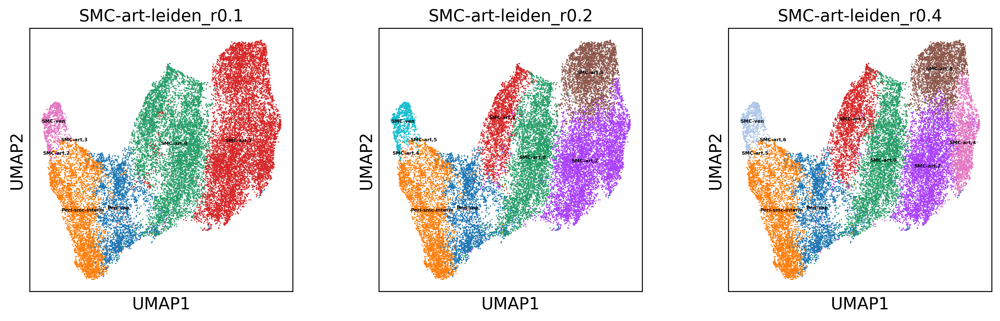

In [66]:
run_leiden(adata_dbrm, resolutions = [0.1, 0.2, 0.4], restrict_to=['SMC-PC_anno', ['SMC-art']], key_name='SMC-art')

In [67]:
adata_dbrm.obs['SMC-art-leiden_r0.1'].value_counts()

SMC-art-leiden_r0.1
SMC-art,1          10443
SMC-art,0           7183
Peri-smc-interm     4419
Peri-cap            2797
SMC-ven              977
SMC-art,2             13
SMC-art,3              1
Name: count, dtype: int64

In [69]:
adata_dbrm.obs['SMC-PC_anno2'] = adata_dbrm.obs['SMC-art-leiden_r0.1'].apply(lambda x: 'SMC-ven' if x in ['SMC-art,2', 'SMC-art,3'] else
                                                                  'SMC-art1' if x == 'SMC-art,1' else
                                                                  'SMC-art2' if x == 'SMC-art,0' else x)

In [88]:
sum(adata_dbrm.obs['SMC-PC_anno2'].isnull())

0

In [108]:
def scvi_markers_enrich(vae, cluster, adata, prep_vae = True, enrich = True, n_markers=5):
    from math import isnan
    if prep_vae:
        vae.adata.obs[cluster] = adata.obs.reindex(vae.adata.obs_names)[cluster].copy()
    results = {}
    de_mrks_dict = {}
    de_df = vae.differential_expression(groupby=cluster)
    de_df['cluster'] = [i.replace(" vs Rest","") for i in de_df['comparison']]
    de_df.head()
    markers = {}
    cats = vae.adata.obs[cluster].unique().tolist()
    for i, c in enumerate(cats):
        if not pd.isna(c):
            cid = "{} vs Rest".format(c)
            cell_type_df = de_df.loc[de_df.comparison == cid]
            cell_type_df = cell_type_df[cell_type_df.lfc_mean > 1]
            cell_type_df = cell_type_df[cell_type_df["bayes_factor"] > 2]
            cell_type_df = cell_type_df[cell_type_df["non_zeros_proportion1"] > 0.1]
            de_mrks_dict[c]=cell_type_df.index.tolist() 
            markers[c] = cell_type_df.index.tolist()[:n_markers]
    if enrich:
        enrich_df = sc.queries.enrich(de_mrks_dict,gprofiler_kwargs={'sources': ['GO:BP', 'REAC', 'KEGG'], 
                                                                     'no_evidences': False, 'all_results': True}, 
                                      org="hsapiens")
        enrich_df.significant = enrich_df.p_value<0.1
        enrich_df = enrich_df.loc[((enrich_df.term_size > 10) & (enrich_df.term_size < 500)) & (enrich_df.significant == True)].reset_index(drop = True)
        print(f"Number of significant genes:{str(enrich_df.significant.sum())}")
    results['de_df'] = de_df
    results['markers'] = markers
    if enrich:
        results['enrich'] = enrich_df
    #print(results)
    return(results)


In [72]:
model_path

'/nfs/team205/vk8/projects/thymus_ageing_atlas/FB_Vascular_compartment/models'

In [73]:
vae = scvi.model.SCVI.load(f"{model_path}/thyAgeing_scvi_v3_2024-11-05_tec-fb-vascSplit_smc-pc_v2_2layers_300epochs_batch-sample2025-01-27")

INFO     File                                                                                                      
         /nfs/team205/vk8/projects/thymus_ageing_atlas/FB_Vascular_compartment/models/thyAgeing_scvi_v3_2024-11-05_
         tec-fb-vascSplit_smc-pc_v2_2layers_300epochs_batch-sample2025-01-27/model.pt already downloaded           


Unable to initialize backend 'cuda': 
Unable to initialize backend 'rocm': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'
Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory


In [109]:
smc_pc_mrkrs = scvi_markers_enrich(vae = vae, cluster = 'SMC-PC_anno2', adata = adata_dbrm, prep_vae = True,
                    enrich = True, n_markers=5)

DE...: 100%|██████████████████████████████████████| 5/5 [01:07<00:00, 13.55s/it]
Number of significant genes:545


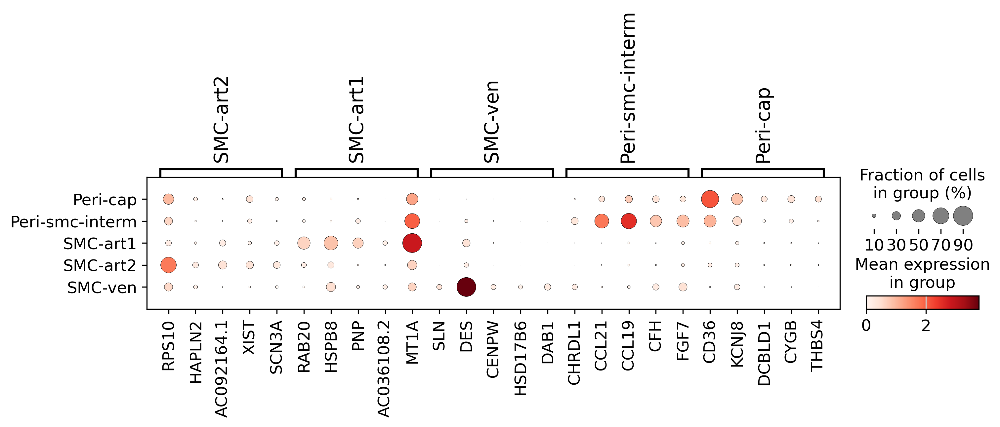

In [110]:
sc.pl.dotplot(adata_dbrm, var_names = smc_pc_mrkrs['markers'], groupby = 'SMC-PC_anno2')

In [ ]:
['RPS10', 'HAPLN2', 'XIST', 'RAB20', 'PNP', 'HSPB8']

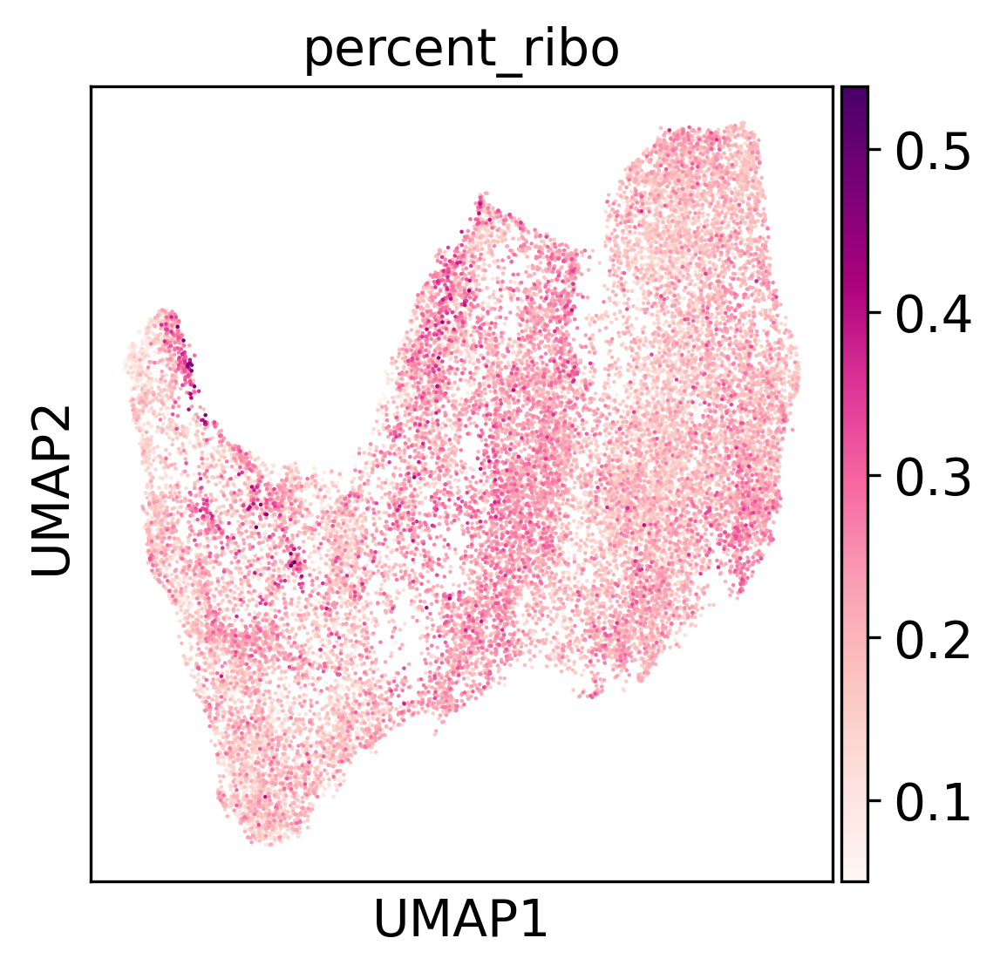

In [111]:
sc.pl.umap(adata_dbrm, color = 'percent_ribo')

In [ ]:
### Load data and inspect

In [8]:
adata = ad.read_h5ad(f'{data_path}/objects/thyAgeing_scvi_v3_2024-11-05_tec-fb-vascSplit_smc-pc_v2_2layers_300epochs_batch-sample2025-01-27.zarr')

In [14]:
annos = pd.read_csv(f'{data_path}/objects/thyAgeing_smc-pc_v2_2layers_300epochs_batch-sample2025-01-27_anno1.csv', index_col = 0)

In [16]:
adata.obs['SMC-PC_anno'] = annos.reindex(adata.obs_names)['SMC-PC_anno'].copy()

In [19]:
doublet_clusters = [i for i in adata.obs['SMC-PC_anno'].unique().tolist() if 'doublet' in i]

In [20]:
adata_dbrm = adata[~adata.obs['SMC-PC_anno'].isin(doublet_clusters),].copy()

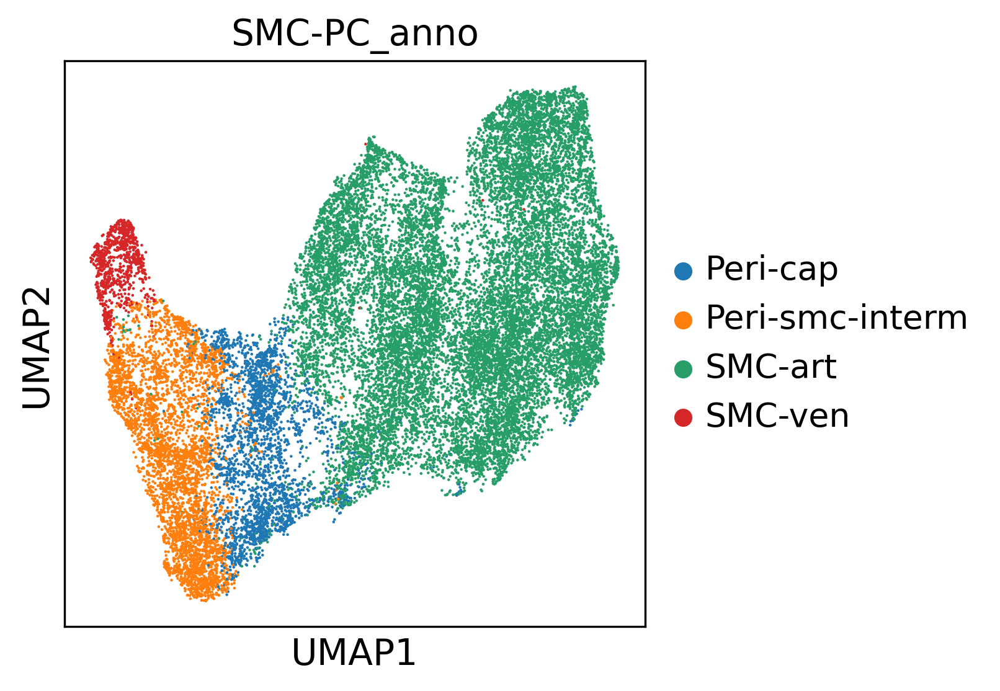

AnnData object with n_obs × n_vars = 25833 × 35530
    obs: 'barcode', 'sample', 'library', 'index', 'library_tcr_ab', 'library_tcr_gd', 'library_bcr', 'path_raw_gex', 'starsolo_version', 'path_cellbender_gex', 'path_cellranger_arc', 'donor', 'chemistry_simple', 'chemistry_detail', 'chemistry_orig', 'origin_institute', 'research_no', 'study', 'sort', 'sort_type', 'in_HTSA', 'public_data', 'type', 'cite', 'health_status', 'age_group', 'age_group2', 'age', 'age_num', 'age_unit', 'age_cont', 'sex', 'age_months', 'path_tcr_ab', 'path_tcr_gd', 'path_bcr', 'comment', 'n_counts', 'n_genes', 'percent_mito', 'percent_ribo', 'percent_hb', 'scrublet_score', 'predicted_doublet', 'taa_l5', 'taa_l4', 'taa_l3', 'taa_l2', 'taa_l1', 'taa_l0', 'doublet', 'stroma-anno1-coarse', 'stroma-anno1-granular', 'stroma-anno2-coarse', 'stroma-anno2-granular', 'doublet_verbose', 'SMC-PC_anno'
    var: 'gene_ids', 'gene_name', 'n_counts', 'n_cells'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'age_cont_colors', 'age

In [21]:
regen_embed(adata_dbrm, 'SMC-PC_anno')

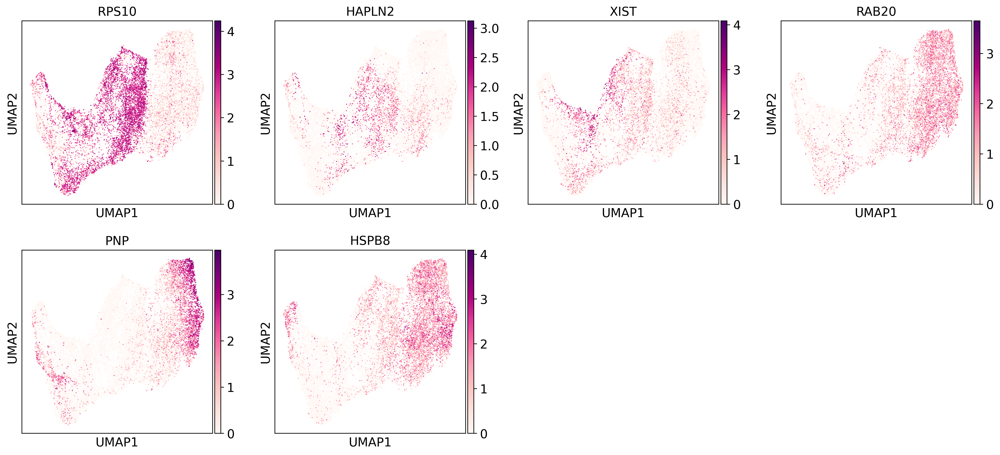

In [22]:
sc.pl.umap(adata_dbrm, color = ['RPS10', 'HAPLN2', 'XIST', 'RAB20', 'PNP', 'HSPB8'] )

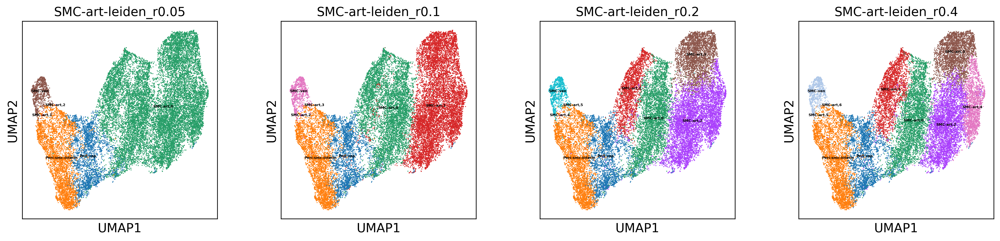

In [24]:
run_leiden(adata_dbrm, resolutions = [0.05, 0.1, 0.2, 0.4], restrict_to=['SMC-PC_anno', ['SMC-art']], key_name='SMC-art')

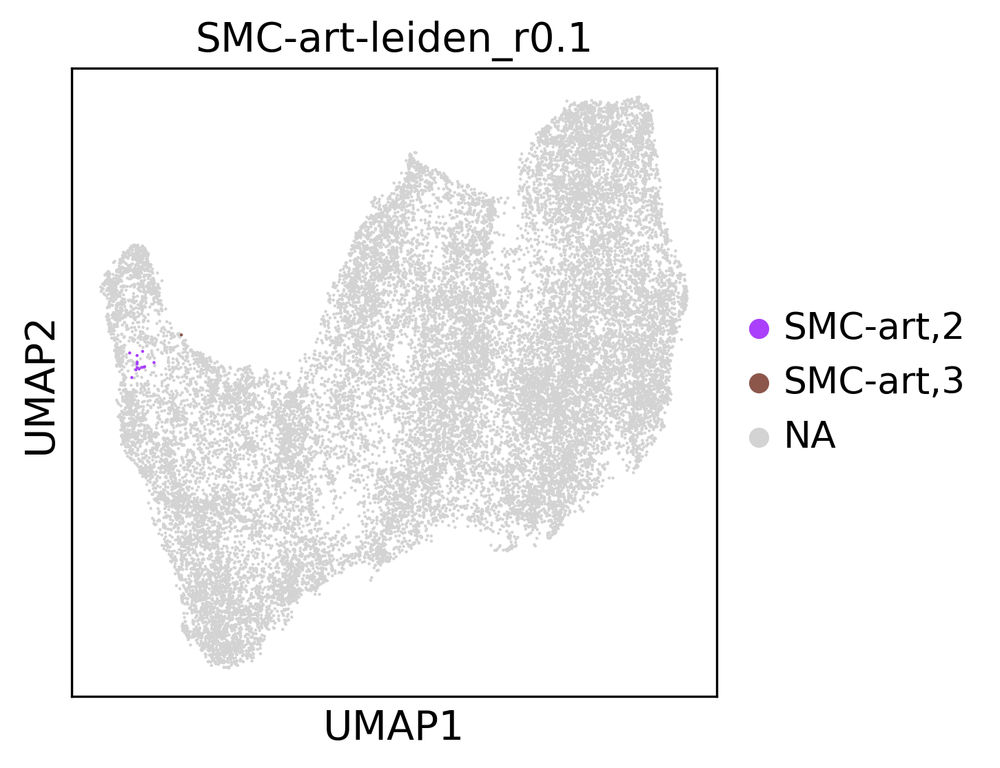

In [28]:
sc.pl.umap(adata_dbrm, color = 'SMC-art-leiden_r0.1', groups = ['SMC-art,2', 'SMC-art,3'])

In [30]:
sc.tl.dendrogram(adata_dbrm, use_rep = 'X_scVI', groupby='SMC-art-leiden_r0.1')

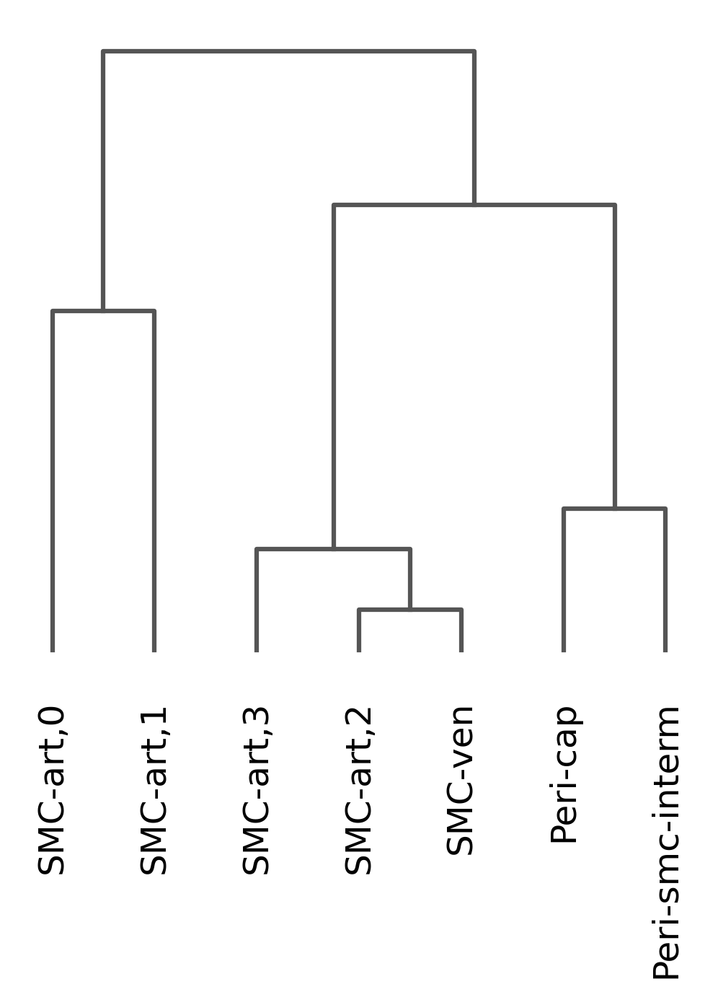

<Axes: >

In [31]:
sc.pl.dendrogram(adata_dbrm, groupby='SMC-art-leiden_r0.1')

In [35]:
adata_dbrm.obs['SMC-PC_anno2'] = adata_dbrm.obs['SMC-art-leiden_r0.1'].apply(lambda x:
                                                'SMC-ven' if x in ['SMC-art,2', 'SMC-art,3'] else
                                                'SMC-art1' if x == 'SMC-art,1' else
                                                 'SMC-art2' if x == 'SMC-art,0' else x)

In [27]:
adata_dbrm.obs['SMC-art-leiden_r0.1'].value_counts()

SMC-art-leiden_r0.1
SMC-art,1          10443
SMC-art,0           7183
Peri-smc-interm     4419
Peri-cap            2797
SMC-ven              977
SMC-art,2             13
SMC-art,3              1
Name: count, dtype: int64

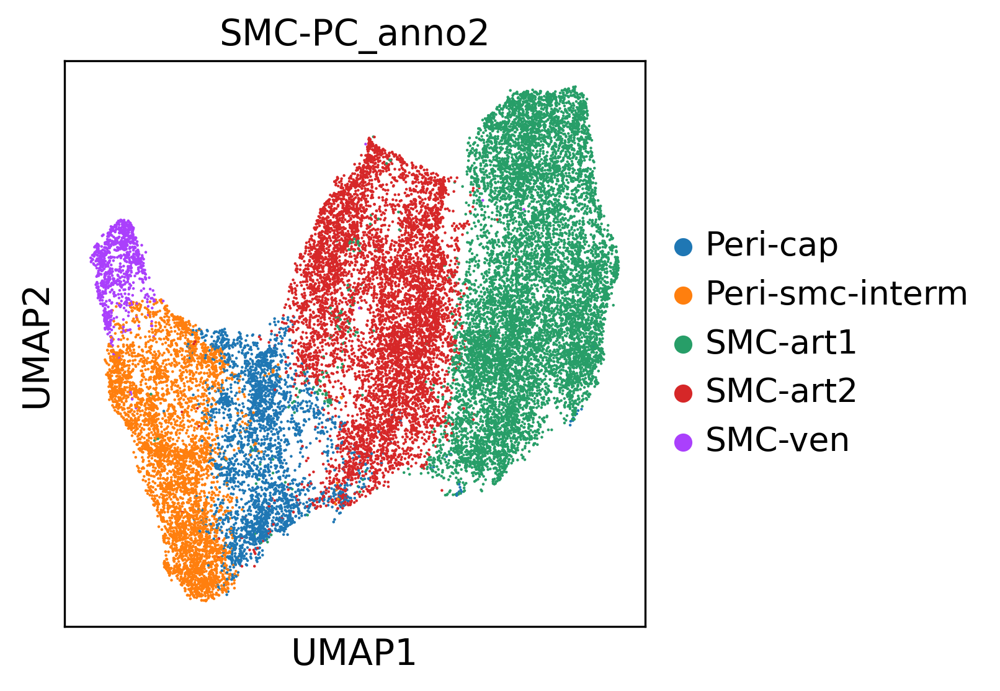

In [36]:
sc.pl.umap(adata_dbrm, color = 'SMC-PC_anno2')

In [40]:
annos['SMC-PC_anno3'] = adata_dbrm.obs.reindex(annos.index)['SMC-PC_anno2'].copy()

In [44]:
annos.rename(columns = {'SMC-PC_anno':'SMC-PC_anno2'}, inplace = True)

In [52]:
annos['SMC-PC_anno'] = annos.apply(lambda x: x['SMC-PC_anno2'] if pd.isna(x['SMC-PC_anno3']) else 
                                  x['SMC-PC_anno3'], axis = 1)

In [57]:
annos

,SMC-PC_anno1,SMC-PC_anno2,SMC-PC_anno3,SMC-PC_anno
names,,,,
D3_CD45depl-ACCGTAAGTAAGTTCC,SMC-EC-doublet,SMC-EC-doublet,NaN,SMC-EC-doublet
D3_CD45depl-GGCGTGTTCATCGATG,SMC-EC-doublet,SMC-EC-doublet,NaN,SMC-EC-doublet
D3_CD45depl-ACATACGAGCTACCGC,SMC-EC-doublet,SMC-EC-doublet,NaN,SMC-EC-doublet
TA10139060-CTTACCGCACGGACAA,SMC-Fb-doublet,SMC-Fb-doublet,NaN,SMC-Fb-doublet
TEC_112-TGAGCGCGTACCCGAC,SMC-EC-doublet,SMC-EC-doublet,NaN,SMC-EC-doublet
...,...,...,...,...
TEC_96-ATCACGAAGTGCAGCA,cap_pc,Peri-cap,Peri-cap,Peri-cap
TEC_96-AGTAGCTCAATATCCG,smc_pc_intermediate,Peri-smc-interm,Peri-smc-interm,Peri-smc-interm
TEC_96-GTAATGCCAGCTGTGC,cap_pc,Peri-cap,Peri-cap,Peri-cap


In [55]:
annos.to_csv(f'{data_path}/objects/thyAgeing_smc-pc_v2_2layers_300epochs_batch-sample2025-03-03_anno2.csv')